# M13.11 — Análisis de la referencia bayesiana (R, H) por régimen

Protocolo: `docs/experiments/M13_11_bayesian_reference.md` (pre-registro y enmiendas 2–7). Local, CPU. Sin inferencia ni PE: solo lee.

**Entradas** (`<data_root>/results/M13_3/M13_11/`):
- `rom_rows_20261106T173402Z/selection.json` — selección (default_rng(131101)), regímenes τ30 D1–D2 / D5–D6 / D9–D10.
- `rom_rows_20261106T173402Z/pe_8s_marg_ns5000_nlive500_walks100_eps0.03_dinverse_square/row_<i>.json|.npz` — banco marginalizado (enmienda 7). Solo filas con `.json` (terminadas). El directorio sin marginalizar (`pe_8s_nlive500_…`) y el de la prueba de la enmienda 5 (`pe_test_marg_…`) **no entran**.
- `gnet_<UTC>.npz` — `scripts/m13/m13_11_predict_rom_rows.py` (VM): μ, Σ de 4a-G3T s123, M14.5a y M14.5b sobre las filas con señal ROM y sobre las mismas filas originales de val G3T; gate G-NET.
- `preds_val_G3T` (o el npz de val de 4a-G3T) de cada red — solo si el numerador de R usa todas las filas de val del régimen.

**Redes** (enmiendas 2, 6, 7): 4a-G3T s123 = primaria (criterio pre-registrado); M14.5a = descriptiva; M14.5b = modelo final de M14 (se informa).

**Enmienda 8 (20-11-2026), implementada literalmente:**
1. G-NET relativo ≤ 0,02, unidades físicas, por red/régimen/etiqueta, sobre las 180 filas; un fallo invalida solo esa celda.
2. Numerador de R: MSE de la red sobre todas las filas de val del régimen con señal S15. R emparejado (secundario): filas con PE, señal ROM.
3. IC del 95 % por percentiles, 2000 réplicas; en R, numerador y denominador remuestreados por separado; en el R emparejado, remuestreo conjunto de filas.
4. Global: solo descriptivo, media de los tres regímenes con igual peso; criterios por régimen.
5. Gate de cobertura: intervalos centrales del 50 % y 90 % de 𝓜 y χ_eff; filas primarias del banco agregadas; región de aceptación central de Binomial(n, p) al 98,75 % por prueba (Bonferroni, 4 pruebas). Por régimen, descriptivo.
6. Completitud: todas las filas del banco (40 por régimen en el intermedio, 60 en el final) terminadas; se excluyen las del test de la enmienda 5.
7. sampler_missed_mode = True: la PE se repite una vez con nlive 1000 (resto igual); si persiste, la fila se excluye y se informa; con > 2 filas excluidas en un régimen, ese régimen es no concluyente.
8. Σ_ii frente a la varianza posterior para M14.5a y M14.5b.

**Modos.** `MODE = "real"` se niega a calcular si el banco no está completo o si quedan filas con `sampler_missed_mode = True` sin repetir (las lista con el comando de repetición). `MODE = "synthetic"` genera posteriores y predicciones falsas con la misma estructura, para probar el código; sus números no significan nada. `MODE = "gnet_only"` ejecuta solo la sección 0 (G-NET en detalle, descriptiva; lee `GNET_FILE`) y se para.

In [1]:
# ---- Configuración -----------------------------------------------------------------------------------------------
MODE = "gnet_only"            # "real" | "synthetic" | "gnet_only" (solo la sección 0, G-NET en detalle)
N_PER_REGIME = 40             # 40: análisis intermedio (plan del 6-11); 60: final (toda la selección)
STAGE = "intermedio" if N_PER_REGIME == 40 else "final"
ROM_STAMP = "rom_rows_20261106T173402Z"
PE_DIR_NAME = "pe_8s_marg_ns5000_nlive500_walks100_eps0.03_dinverse_square"   # enmienda 7
GNET_FILE = "gnet_20261120T152642Z.npz"              # None | "gnet_<UTC>.npz" de m13_11_predict_rom_rows.py (obligatorio en modo real)

# Enmienda 8 (fijado; no cambiar).
NUMERATOR_ROWS = "val_regime_S15"    # punto 2: todas las filas de val del régimen, señal S15
CI_LEVEL = 0.95                      # punto 3: percentiles
N_BOOT = 2000                        # punto 3
GLOBAL_DEF = "mean_of_regimes"       # punto 4: descriptivo, igual peso
CRED_INTERVAL = "central"            # punto 5: colas iguales
COVERAGE_ROWS = "primary"            # punto 5: filas primarias del banco, agregadas
BINOM_LEVEL = 0.9875                 # punto 5: región de aceptación central por prueba (Bonferroni, 4 pruebas)
REPEAT_NLIVE = 1000                  # punto 7: repetición de filas con sampler_missed_mode = True
MAX_EXCLUDED_PER_REGIME = 2          # punto 7: con más de 2 excluidas, el régimen es no concluyente
BOOT_SEED = 131120                   # semilla del bootstrap (técnica)
# ------------------------------------------------------------------------------------------------------------------

In [2]:
from pathlib import Path
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.paths import resolve_data_root
from scripts.m13.m13_1_diagnostics import tau_newtonian   # tau30 de la selección (m13_11_prepare_rows.select_rows)

assert MODE in ("real", "synthetic", "gnet_only"), MODE
assert N_PER_REGIME in (40, 60), N_PER_REGIME
assert (NUMERATOR_ROWS, CI_LEVEL, N_BOOT, GLOBAL_DEF, CRED_INTERVAL, COVERAGE_ROWS, BINOM_LEVEL, REPEAT_NLIVE,
        MAX_EXCLUDED_PER_REGIME) == ("val_regime_S15", 0.95, 2000, "mean_of_regimes", "central", "primary", 0.9875,
                                     1000, 2), "Configuración distinta de la enmienda 8"

# Pre-registro.
LABELS = ["chirp_mass", "total_mass", "chi_eff"]          # orden de todos los artefactos
PRIMARY_LABELS = ["chi_eff", "chirp_mass"]                 # total_mass: descriptivo
REGIMES = ("short", "medium", "long")                      # D1–D2, D5–D6, D9–D10 (m13_11_prepare_rows.REGIMES)
REGIME_DECILES = {"short": (0, 1), "medium": (4, 5), "long": (8, 9)}
H_RELEVANT = 0.15     # margen relevante: límite inferior del IC de H >= 15 %
H_NONE = 0.07         # sin margen: límite superior del IC de H < 7 %
COVERAGE_LEVELS = (0.5, 0.9)
COVERAGE_LABELS = ["chi_eff", "chirp_mass"]
TEST_POSITIONS = (40, 43)   # enmienda 5 (= m13_11_run_pe.TEST_POSITIONS), más la fila más larga del régimen largo
NETS = {"4a_G3T": "4a-G3T s123 (primaria)", "M14_5a": "M14.5a (descriptiva)", "M14_5b": "M14.5b (modelo final)"}
SIGMA_NETS = ["M14_5a", "M14_5b"]   # descriptivo Σ_ii frente a la varianza posterior (enmienda 8, punto 8)
VAL_REFERENCE = {   # npz de val G3T de cada red (los mismos que comprueba m13_11_predict_rom_rows.py)
    "4a_G3T": "results/M13_3/M13_13_4a_G3T_s123/val_predictions_embeddings.npz",
    "M14_5a": "results/M13_3/M14_5a_4a_G3T_fullcov_s123/preds_val_G3T/val_predictions_embeddings.npz",
    "M14_5b": "results/M13_3/M14_5b_4a_G3T_tbank_fullcov_s123/preds_val_G3T/val_predictions_embeddings.npz",
}
EXPECTED_SETTINGS = dict(marginalize=True, vector_samples=5000, nlive=500, walks=100, epsilon=0.03, dlogz=0.1,
                         distance_prior="inverse_square")
EXPECTED_VERSIONS = dict(pycbc="2.9.0", dynesty="2.1.5")   # plan del banco (6-11)
GNET_MAX_REL = 0.02   # enmiendas 2 y 8 (punto 1)
# Directorio de la repetición: mismo nombre que da m13_11_run_pe.py con --nlive 1000 y el resto por defecto.
REPEAT_DIR_NAME = PE_DIR_NAME.replace("_nlive500_", f"_nlive{REPEAT_NLIVE}_")
assert REPEAT_DIR_NAME != PE_DIR_NAME
print(f"MODE {MODE}, análisis {STAGE} ({N_PER_REGIME} filas por régimen), numerador {NUMERATOR_ROWS}, "
      f"IC {CI_LEVEL:.0%} ({N_BOOT} réplicas), global {GLOBAL_DEF} (descriptivo)")

MODE gnet_only, análisis intermedio (40 filas por régimen), numerador val_regime_S15, IC 95% (2000 réplicas), global mean_of_regimes (descriptivo)


## 0. G-NET en detalle (descriptivo)

No cambia ningún veredicto (G-NET y los criterios se aplican en las secciones 5 y 6). Solo lee `gnet_<UTC>.npz`, no las PE, así que se puede ejecutar ya: con `MODE = "gnet_only"`, «Run All» ejecuta la configuración, la celda común y esta sección, y se para al final de ella. En modo sintético usa μ y σ falsos; en modo real, el `GNET_FILE` de la configuración.

Por red, régimen y etiqueta, sobre las 180 filas seleccionadas:
1. Diferencia relativa con signo (RMSE_ROM − RMSE_S15) / RMSE_S15, con IC del 95 % por bootstrap emparejado de filas dentro del régimen (2000 réplicas; las mismas filas para ROM y S15). El gate usa su valor absoluto.
2. Δμ = μ_ROM − μ_S15 por fila, en unidades físicas y, para las redes full-cov (M14.5a, M14.5b), en unidades de la σ de la red sobre la entrada original S15 (σ_S15, de Σ_S15). 4a-G3T: solo físicas. Mediana de |Δμ| (y de |Δμ|/σ), fracción con Δμ > 0 y test de signo bilateral (binomial con p = 1/2, sin las filas con Δμ = 0).
3. Figura: Δμ/σ (4a-G3T: Δμ físico) frente a τ30 de la masa chirp verdadera, por red y etiqueta.

In [3]:
GNET_DETAIL_N_BOOT = 2000
GNET_DETAIL_SEED = 131121
GNET_DETAIL_LABELS = ["chirp_mass", "total_mass", "chi_eff"]
GNET_DETAIL_REGIMES = ("short", "medium", "long")
GNET_DETAIL_NETS = ["4a_G3T", "M14_5a", "M14_5b"]

if MODE == "synthetic":
    _rng = np.random.default_rng(20261121)
    _reg = np.repeat(np.array(GNET_DETAIL_REGIMES), 60)
    _scale = {"short": [2.0, 4.0, 0.12], "medium": [0.25, 1.5, 0.08], "long": [0.02, 0.8, 0.05]}
    _S = np.array([_scale[k] for k in _reg])
    _y = np.array([[35.0, 90.0, 0.0], [17.0, 45.0, 0.0], [8.0, 20.0, 0.0]])[np.repeat([0, 1, 2], 60)] \
        * (1 + 0.05 * _rng.standard_normal((180, 3)))
    gd = dict(regime=_reg, y_true=_y, mu_rom={}, mu_s15={}, sigma_s15={})
    for _net, _c in {"4a_G3T": 1.6, "M14_5a": 1.3, "M14_5b": 1.05}.items():
        _e = np.sqrt(_c) * _S * _rng.standard_normal(_S.shape)
        gd["mu_s15"][_net] = _y + _e
        gd["mu_rom"][_net] = _y + _e + 0.05 * _S * (_rng.standard_normal(_S.shape) + 0.3)
        if _net != "4a_G3T":
            gd["sigma_s15"][_net] = np.sqrt(_c) * _S
else:
    assert GNET_FILE is not None, "Fijar GNET_FILE"
    _path = resolve_data_root() / "results" / "M13_3" / "M13_11" / GNET_FILE
    with np.load(_path, allow_pickle=False) as z:
        assert [str(x) for x in z["label_names"]] == GNET_DETAIL_LABELS
        _ym, _ys = z["y_mean"].astype(np.float64), z["y_std"].astype(np.float64)
        gd = dict(regime=z["regime"].astype(str), y_true=z["y_true"].astype(np.float64),
                  mu_rom={}, mu_s15={}, sigma_s15={})
        for _net in GNET_DETAIL_NETS:   # a unidades físicas; σ escala con y_std (escalado lineal por etiqueta)
            gd["mu_rom"][_net] = z[f"mu_rom_{_net}"] * _ys + _ym
            gd["mu_s15"][_net] = z[f"mu_s15_{_net}"] * _ys + _ym
            if f"sigma_s15_{_net}" in z.files:
                gd["sigma_s15"][_net] = z[f"sigma_s15_{_net}"] * _ys
    print("gnet:", _path)
gd["tau30"] = tau_newtonian(gd["y_true"][:, 0])
print({k: int(np.sum(gd["regime"] == k)) for k in GNET_DETAIL_REGIMES}, "filas por régimen")

gnet: /data/vserrano/cbc_pe_data/results/M13_3/M13_11/gnet_20261120T152642Z.npz
{'short': 60, 'medium': 60, 'long': 60} filas por régimen


In [4]:
def sign_test(d):
    # Bilateral, binomial con p = 1/2, sin ceros.
    d = d[d != 0]
    n, k = d.size, int(np.sum(d > 0))
    p = min(1.0, 2 * min(stats.binom.cdf(k, n, 0.5), stats.binom.sf(k - 1, n, 0.5))) if n else np.nan
    return k, n, p


_rng = np.random.default_rng(GNET_DETAIL_SEED)
detail = []
for net in GNET_DETAIL_NETS:
    for k in GNET_DETAIL_REGIMES:
        m = gd["regime"] == k
        y, a, b = gd["y_true"][m], gd["mu_rom"][net][m], gd["mu_s15"][net][m]
        e_rom, e_s15 = (a - y) ** 2, (b - y) ** 2
        rel = np.sqrt(e_rom.mean(0)) / np.sqrt(e_s15.mean(0)) - 1
        idx = _rng.integers(0, m.sum(), (GNET_DETAIL_N_BOOT, m.sum()))   # mismas filas para ROM y S15
        rel_b = np.sqrt(e_rom[idx].mean(1)) / np.sqrt(e_s15[idx].mean(1)) - 1   # (n_boot, 3)
        lo, hi = np.quantile(rel_b, [0.025, 0.975], axis=0)
        d = a - b
        s = gd["sigma_s15"].get(net)
        for j, lab in enumerate(GNET_DETAIL_LABELS):
            kpos, n, p = sign_test(d[:, j])
            row = dict(net=net, regime=k, label=lab, n=int(m.sum()), rel_diff=rel[j], rel_lo=lo[j], rel_hi=hi[j],
                       abs_rel_le_002=bool(abs(rel[j]) <= 0.02), median_abs_dmu=np.median(np.abs(d[:, j])),
                       median_abs_dmu_over_sigma=(np.median(np.abs(d[:, j]) / s[m][:, j]) if s is not None
                                                  else np.nan),
                       frac_dmu_pos=kpos / n if n else np.nan, sign_test_p=p)
            detail.append(row)
gnet_detail = pd.DataFrame(detail).set_index(["net", "regime", "label"])
with pd.option_context("display.float_format", "{:.4g}".format):
    display(gnet_detail)

n   rel_diff     rel_lo    rel_hi  abs_rel_le_002  \
net    regime label                                                            
4a_G3T short  chirp_mass  60   -0.01546   -0.04308 9.966e-05            True   
              total_mass  60   -0.02031   -0.04303 -0.006116           False   
              chi_eff     60    0.01188   -0.01445   0.04355            True   
       medium chirp_mass  60   0.002783  -0.005745   0.01203            True   
              total_mass  60   0.001458   -0.00861   0.01238            True   
              chi_eff     60 -0.0004613  -0.009065   0.01098            True   
       long   chirp_mass  60   0.006288 -0.0008301   0.01771            True   
              total_mass  60  -0.004945    -0.0216  0.009345            True   
              chi_eff     60  -0.001122  -0.005583   0.00275            True   
M14_5a short  chirp_mass  60   -0.01902   -0.04501 -0.002571            True   
              total_mass  60   -0.02254   -0.05083 -0.005917           False   
              chi_eff     60    0.01506   -0.01541   0.05255            True   
       medium chirp_mass  60  -0.002376  -0.008232  0.004116            True   
              total_mass  60 -0.0009744  -0.007413  0.006447            True   
              chi_eff     60   0.001414  -0.005684  0.008861            True   
       long   chirp_mass  60   0.006665   -0.01197   0.02574            True   
              total_mass  60  -0.005644   -0.01926   0.00496            True   
              chi_eff     60  -0.000814  -0.004677  0.002873            True   
M14_5b short  chirp_mass  60   -0.02185    -0.0484 -0.004638           False   
              total_mass  60   -0.02842   -0.04946  -0.01277           False   
              chi_eff     60    0.01111  -0.009467   0.03561            True   
       medium chirp_mass  60   0.002469  -0.004296  0.009903            True   
              total_mass  60    0.00487  -0.002335   0.01336            True   
              chi_eff     60   0.003645  -0.002486  0.009794            True   
       long   chirp_mass  60   0.002978  -0.005431    0.0203            True   
              total_mass  60  -0.007119   -0.02659  0.006751            True   
              chi_eff     60  -0.001244   -0.00493  0.001996            True   

                          median_abs_dmu  median_abs_dmu_over_sigma  \
net    regime label                                                   
4a_G3T short  chirp_mass          0.1831                        NaN   
              total_mass          0.3409                        NaN   
              chi_eff           0.006442                        NaN   
       medium chirp_mass         0.04826                        NaN   
              total_mass          0.1197                        NaN   
              chi_eff           0.002909                        NaN   
       long   chirp_mass        0.005483                        NaN   
              total_mass         0.03823                        NaN   
              chi_eff           0.001071                        NaN   
M14_5a short  chirp_mass          0.2315                    0.03646   
              total_mass          0.4305                    0.04808   
              chi_eff           0.005624                     0.0313   
       medium chirp_mass         0.05186                    0.01365   
              total_mass          0.1307                    0.01612   
              chi_eff           0.002332                    0.01541   
       long   chirp_mass        0.006502                    0.00723   
              total_mass         0.03841                    0.00874   
              chi_eff           0.001145                   0.009553   
M14_5b short  chirp_mass          0.1833                    0.03171   
              total_mass          0.3501                    0.03817   
              chi_eff           0.005605                    0.03068   
       medium chirp_mass         0.05117                    0.01306   
  

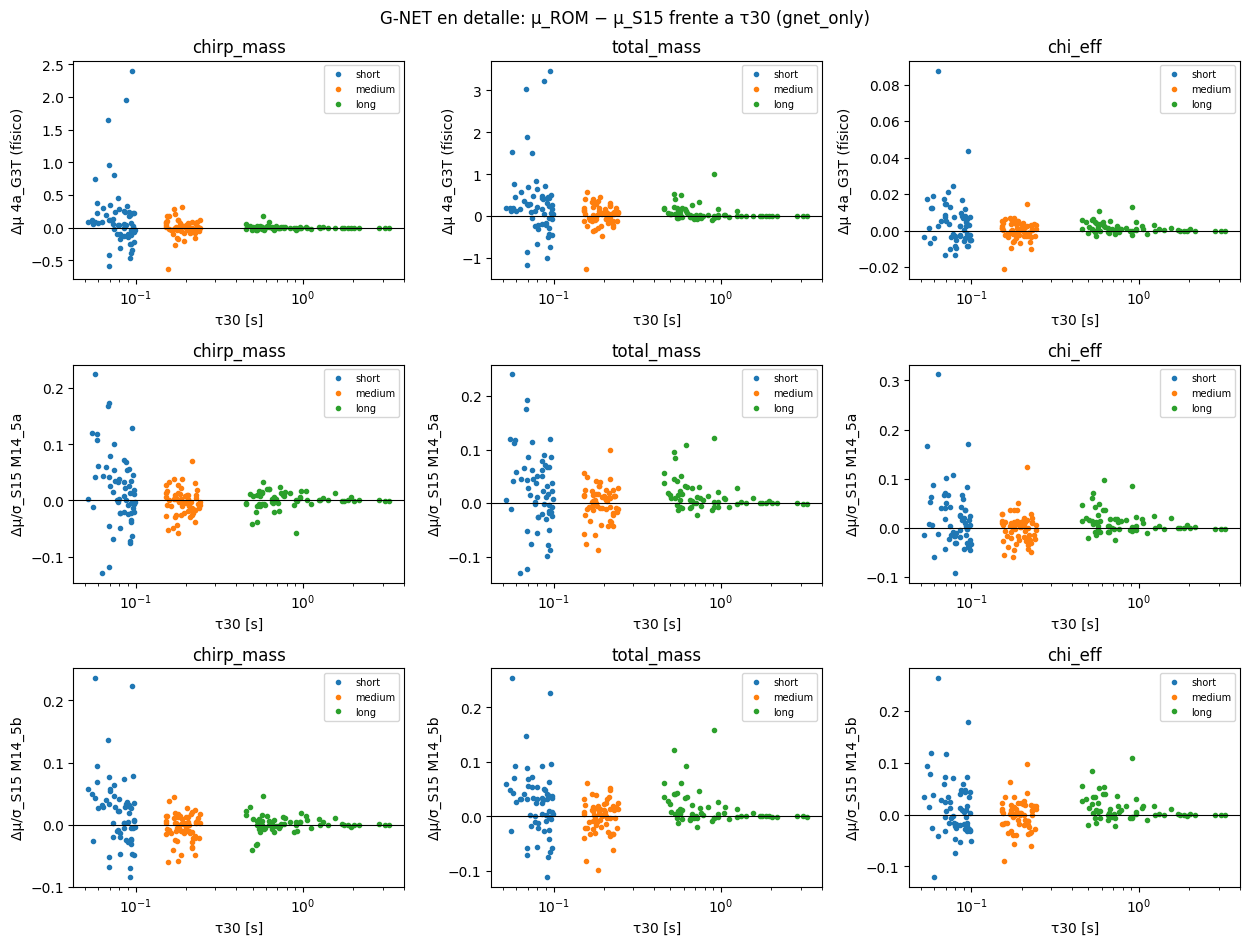

RuntimeError: MODE = 'gnet_only': fin de la sección G-NET en detalle; el análisis no se ejecuta.

In [5]:
fig, axes = plt.subplots(len(GNET_DETAIL_NETS), len(GNET_DETAIL_LABELS),
                         figsize=(4.2 * len(GNET_DETAIL_LABELS), 3.2 * len(GNET_DETAIL_NETS)), squeeze=False)
for a, net in enumerate(GNET_DETAIL_NETS):
    d = gd["mu_rom"][net] - gd["mu_s15"][net]
    s = gd["sigma_s15"].get(net)
    for j, lab in enumerate(GNET_DETAIL_LABELS):
        ax = axes[a, j]
        val = d[:, j] / s[:, j] if s is not None else d[:, j]
        for k in GNET_DETAIL_REGIMES:
            m = gd["regime"] == k
            ax.semilogx(gd["tau30"][m], val[m], "o", ms=3, label=k)
        ax.axhline(0, color="k", lw=0.8)
        ax.set(xlabel="τ30 [s]", ylabel=(f"Δμ/σ_S15 {net}" if s is not None else f"Δμ {net} (físico)"), title=lab)
        ax.legend(fontsize=7)
fig.suptitle(f"G-NET en detalle: μ_ROM − μ_S15 frente a τ30 ({MODE})")
fig.tight_layout()
plt.show()

if MODE == "gnet_only":
    raise RuntimeError("MODE = 'gnet_only': fin de la sección G-NET en detalle; el análisis no se ejecuta.")

### Lectura de la sección 0 (G-NET en detalle; descriptivo, no cambia ningún veredicto)
- Reproducción exacta de las tres redes sobre las filas S15 (máx. |Δμ| ≤ 9e-7).
- Régimen corto: con señal ROM, el RMSE es menor que con S15. El IC 95 % excluye 0 en M_tot para las tres redes y en 𝓜 para M14.5a y M14.5b (por ejemplo, 5b M_tot −2,8 % [−4,9; −1,3]). Las predicciones con ROM son algo más altas (63–70 % de filas con Δμ > 0; test de signo p ≈ 0,003–0,05): un desplazamiento sistemático hacia la verdad, porque a masa alta la red infraestima.
- Tamaño pequeño: mediana |Δμ|/σ ≈ 0,03–0,05 (corto), 0,01–0,02 (medio), 0,006–0,009 (largo).
- Regímenes medio y largo: diferencias de RMSE compatibles con 0 o ≤ 0,7 %.
- Con 60 filas, el IC de la diferencia de RMSE tiene una anchura de ~±2 %: el umbral de G-NET está en el límite de la resolución. Los veredictos de G-NET (enmienda 8) no cambian.
- Interpretación (hipótesis): la red es sensible a diferencias de forma de onda de ~10⁻³ en el merger-ringdown. Motiva la línea de robustez frente a sistemáticos de forma de onda.

## 1. Funciones comunes (modo real y sintético pasan por las mismas)

In [ ]:
def bank_rows(selection, n_per_regime):
    # = m13_11_run_pe.bank_rows: primeras n filas de cada régimen en el orden de selection.json.
    return {k: [r["row_index"] for r in selection["rows"] if r["regime"] == k][:n_per_regime] for k in REGIMES}


def test_rows(selection):
    # = m13_11_run_pe.test_rows (enmienda 5): posiciones 41–43 de cada régimen y la fila más larga del largo.
    out = {k: [r["row_index"] for r in selection["rows"] if r["regime"] == k][slice(*TEST_POSITIONS)] for k in REGIMES}
    out["long"] = out["long"] + [selection["timing_row_longest_long_regime"]["row_index"]]
    return {i for v in out.values() for i in v}


def records_to_table(records, selection, test_ids, nlive=500):
    # Tabla por fila terminada, con las comprobaciones de cada .json (nlive 1000 solo en las repeticiones).
    sel = {r["row_index"]: r for r in selection["rows"]}
    expected = dict(EXPECTED_SETTINGS, nlive=nlive)
    rows = []
    for rec in records:
        i = int(rec["row_index"])
        s = sel[i]
        assert rec["regime"] == s["regime"], f"fila {i}: régimen"
        st = rec["settings"]
        got = dict(marginalize=st["marginalize"], vector_samples=(st["marginalization"] or {}).get("vector_samples"),
                   nlive=st["nlive"], walks=st["walks"], epsilon=st["epsilon"], dlogz=st["dlogz"],
                   distance_prior=st["distance_prior"])
        assert got == expected, f"fila {i}: configuración {got}"
        ver = {k: rec["provenance"][k] for k in EXPECTED_VERSIONS}
        assert ver == EXPECTED_VERSIONS, f"fila {i}: entorno {ver}"
        rb = rec["relbin_check"]
        assert rec["relbin_ok"] == rb["relbin_ok"] == (rb["max_abs_diff"] <= rb["threshold"]), f"fila {i}: relbin"
        # primary = is_truncated False (enmienda 4) y relbin_ok (m13_11_run_pe.py, fijado antes del banco).
        assert rec["primary"] == (not rec["is_truncated"] and rec["relbin_ok"]), f"fila {i}: primary"
        assert rec["row_class"] == ("truncated_or_edge" if rec["is_truncated"] else "primary"), f"fila {i}: clase"
        row = dict(row_index=i, regime=rec["regime"], primary=bool(rec["primary"]),
                   is_truncated=bool(rec["is_truncated"]), relbin_ok=bool(rec["relbin_ok"]),
                   relbin_max=float(rb["max_abs_diff"]), test_row=i in test_ids, nlive=int(st["nlive"]),
                   missed=rec.get("sampler_missed_mode"), truth_check_error=rec.get("truth_check_error"))
        for lab in LABELS:
            L = rec["labels"][lab]
            assert np.isclose(L["truth"], s["y"][lab], rtol=1e-6, atol=0), f"fila {i}: verdad de {lab}"
            row.update({f"truth_{lab}": L["truth"], f"post_mean_{lab}": L["mean"], f"post_var_{lab}": L["std"] ** 2})
        rows.append(row)
    return pd.DataFrame(rows).set_index("row_index").sort_index()


def check_bank(table, bank, missing):
    # Enmienda 8, punto 6: todas las filas del banco terminadas. Sin comprobación de la verdad (sin
    # sampler_missed_mode) la regla del punto 7 no se puede aplicar: el modo real se para.
    done = {k: int((table.regime == k).sum()) for k in REGIMES}
    print("terminadas por régimen:", done, "| faltan:", {k: len(v) for k, v in missing.items()})
    complete = all(not v for v in missing.values())
    unchecked = table.missed.isna() | table.truth_check_error.notna()
    print(f"sin sampler_missed_mode o con truth_check_error: {list(table.index[unchecked])}")
    print(f"relbin_ok False: {list(table.index[~table.relbin_ok])} (max|Δloglr| máximo {table.relbin_max.max():.3f})")
    print(f"filas del test de la enmienda 5 dentro del banco (excluidas): {list(table.index[table.test_row])}")
    if MODE == "real":
        assert complete, f"Banco incompleto: el análisis {STAGE} necesita las {N_PER_REGIME} filas por régimen"
        assert not unchecked.any(), "Filas sin comprobación de modo perdido: ejecutar --check-truth antes"
    return complete


def apply_missed_rule(table, samples, repeat_table, repeat_samples, rows_dir):
    # Enmienda 8, punto 7. Fila con sampler_missed_mode = True: se usa su repetición con nlive 1000 si ya existe;
    # si en la repetición persiste, la fila se excluye; si aún no se ha repetido, queda pendiente (se lista).
    table, samples = table.copy(), dict(samples)
    status = {}
    for i in table.index[table.missed.astype(bool) & ~table.test_row]:
        if i not in repeat_table.index:
            status[i] = "pendiente de repetir"
        elif pd.isna(repeat_table.at[i, "missed"]) or not pd.isna(repeat_table.at[i, "truth_check_error"]):
            status[i] = "repetida sin comprobación"
        elif bool(repeat_table.at[i, "missed"]):
            status[i] = "persiste: excluida"
        else:
            status[i] = "repetida: se usa la PE con nlive 1000"
            table.loc[i] = repeat_table.loc[i, table.columns]
            samples[i] = repeat_samples[i]
    rep = pd.DataFrame([dict(row_index=i, regime=table.at[i, "regime"], status=s) for i, s in status.items()],
                       columns=["row_index", "regime", "status"])
    display(rep)
    pending = [i for i, s in status.items() if s in ("pendiente de repetir", "repetida sin comprobación")]
    if pending:
        print(f"Repetir con nlive {REPEAT_NLIVE} (resto igual; salida en {rows_dir / REPEAT_DIR_NAME}):")
        for i in pending:
            print(f"  python scripts/m13/m13_11_run_pe.py --rows-dir {rows_dir} --row {i} --nlive {REPEAT_NLIVE}")
    excluded = [i for i, s in status.items() if s == "persiste: excluida"]
    if MODE == "real":
        assert not pending, f"Filas con sampler_missed_mode = True sin repetir (o sin comprobar): {pending}"
    elif pending:
        print("SINTÉTICO: las pendientes se tratan como excluidas para probar el código.")
        excluded += pending
    n_excl = {k: int(sum(table.at[i, "regime"] == k for i in excluded)) for k in REGIMES}
    inconclusive = {k for k, n in n_excl.items() if n > MAX_EXCLUDED_PER_REGIME}
    print(f"excluidas por régimen: {n_excl}; régimen no concluyente (> {MAX_EXCLUDED_PER_REGIME}): "
          f"{sorted(inconclusive) or 'ninguno'}")
    return table, samples, set(excluded), inconclusive


def regime_of_val(y_chirp, tau_edges):
    # = m13_11_prepare_rows.select_rows: tau30 newtoniano de la chirp mass verdadera, deciles de val.
    tdec = np.clip(np.searchsorted(np.asarray(tau_edges)[1:-1], tau_newtonian(y_chirp), side="right"), 0, 9)
    out = np.full(y_chirp.shape, "", dtype=object)
    for k, d in REGIME_DECILES.items():
        out[np.isin(tdec, d)] = k
    return out


def credible_inside(samples, truth, level):
    # Intervalo creíble central (colas iguales), de las muestras de igual peso de la posterior.
    lo, hi = np.quantile(np.asarray(samples, dtype=np.float64), [(1 - level) / 2, (1 + level) / 2])
    return bool(lo <= truth <= hi)


def binomial_ok(k, n, p):
    # Región de aceptación central de Binomial(n, p) al BINOM_LEVEL (bilateral).
    a = 1 - BINOM_LEVEL
    lo, hi = stats.binom.ppf(a / 2, n, p), stats.binom.ppf(1 - a / 2, n, p)
    return bool(lo <= k <= hi), (int(lo), int(hi))


def boot_ratio(groups, rng, n_boot, chunk=200):
    # groups: lista de (num, den, paired) por estrato (régimen); num y den son vectores por fila.
    # Remuestreo dentro de cada estrato; si paired, las mismas filas para numerador y denominador.
    out = {g: [] for g in ("num", "den")}
    for start in range(0, n_boot, chunk):
        b = min(chunk, n_boot - start)
        nums, dens = [], []
        for num, den, paired in groups:
            i_num = rng.integers(0, num.size, (b, num.size))
            i_den = i_num if paired else rng.integers(0, den.size, (b, den.size))
            nums.append(num[i_num].mean(axis=1))
            dens.append(den[i_den].mean(axis=1))
        out["num"].append(np.stack(nums))
        out["den"].append(np.stack(dens))
    return np.concatenate(out["num"], axis=1), np.concatenate(out["den"], axis=1)   # (n_estratos, n_boot)


def r_estimates(groups, rng):
    # R de un régimen, o global = media de los R de los tres regímenes con igual peso (enmienda 8, punto 4).
    # IC por percentiles de la distribución bootstrap de esa misma cantidad.
    point_num = np.array([g[0].mean() for g in groups])
    point_den = np.array([g[1].mean() for g in groups])
    bn, bd = boot_ratio(groups, rng, int(N_BOOT))
    R, Rb = np.mean(point_num / point_den), np.mean(bn / bd, axis=0)
    q = np.quantile(Rb, [(1 - CI_LEVEL) / 2, (1 + CI_LEVEL) / 2])
    return R, q


def H_of(R):
    return 1 - 1 / np.sqrt(R)


def verdict(h_lo, h_hi):
    if h_lo >= H_RELEVANT:
        return "margen relevante"
    if h_hi < H_NONE:
        return "sin margen"
    return "no concluyente"


def gnet_table(mu_rom, mu_s15, y, regime):
    rows = []
    for k in REGIMES:
        m = regime == k
        r_rom = np.sqrt(np.mean((mu_rom[m] - y[m]) ** 2, axis=0))
        r_s15 = np.sqrt(np.mean((mu_s15[m] - y[m]) ** 2, axis=0))
        for j, lab in enumerate(LABELS):
            rel = abs(r_rom[j] - r_s15[j]) / r_s15[j]
            rows.append(dict(regime=k, label=lab, n=int(m.sum()), rmse_rom=r_rom[j], rmse_s15=r_s15[j],
                             rel_diff=rel, passed=bool(rel <= GNET_MAX_REL)))
    return pd.DataFrame(rows)

## 2. Datos sintéticos (solo `MODE = "synthetic"`)

Misma estructura que los `.json`/`.npz` del banco (y de las repeticiones con nlive 1000), el `gnet_<UTC>.npz` y los npz de val. Posteriores gaussianas calibradas; errores de la red con varianza `ratio_true` × varianza posterior (R verdadero conocido), unas pocas filas truncadas, una fila de test dentro del banco del régimen largo y cuatro filas con modo perdido en el régimen medio.

In [ ]:
def make_synthetic(seed=20261120, n_sel=60, n_val=8000, n_post=4000):
    rng = np.random.default_rng(seed)
    post_std = {"short": [2.0, 4.0, 0.12], "medium": [0.25, 1.5, 0.08], "long": [0.02, 0.8, 0.05]}  # Mc, M, χ_eff
    centre = {"short": [35.0, 90.0, 0.0], "medium": [17.0, 45.0, 0.0], "long": [8.0, 20.0, 0.0]}
    ratio_true = {"4a_G3T": 1.6, "M14_5a": 1.3, "M14_5b": 1.05}
    rows, idx = [], 100000
    for k in REGIMES:
        for p in range(n_sel):
            y = np.array(centre[k]) * (1 + 0.05 * rng.standard_normal(3))
            y[2] = rng.uniform(-0.5, 0.5)
            rows.append(dict(row_index=idx, regime=k, tau30_s=float(tau_newtonian(y[0])), y=dict(zip(LABELS, y))))
            idx += 7
    long_rows = [r for r in rows if r["regime"] == "long"]
    selection = dict(rows=rows, timing_row_longest_long_regime=long_rows[5], tau_edges_s=None)
    bank = bank_rows(selection, N_PER_REGIME)

    def fake_pe(r, nlive, missed, trunc):
        s = np.array(post_std[r["regime"]])
        y = np.array([r["y"][lab] for lab in LABELS])
        draws = y + s * rng.standard_normal(3) + s * rng.standard_normal((n_post, 3))
        rb = float(rng.uniform(0.0, 0.03))
        rec = dict(row_index=r["row_index"], regime=r["regime"], is_truncated=trunc,
                   row_class="truncated_or_edge" if trunc else "primary",
                   relbin_check=dict(max_abs_diff=rb, threshold=0.2, relbin_ok=True), relbin_ok=True,
                   primary=not trunc, sampler_missed_mode=missed,
                   labels={lab: dict(mean=float(draws[:, j].mean()), std=float(draws[:, j].std()),
                                     truth=float(y[j])) for j, lab in enumerate(LABELS)},
                   settings=dict(marginalize=True, marginalization=dict(vector_samples=5000), nlive=nlive,
                                 walks=100, epsilon=0.03, dlogz=0.1, distance_prior="inverse_square"),
                   provenance=dict(EXPECTED_VERSIONS))
        return rec, {lab: draws[:, j] for j, lab in enumerate(LABELS)}

    # Régimen medio: 4 filas con modo perdido; repetida y recuperada, dos persisten, una sin repetir
    # (3 excluidas > 2: el régimen medio sale no concluyente, para probar la regla).
    medium = bank["medium"]
    missed_plan = {medium[0]: False, medium[1]: True, medium[2]: True, medium[3]: None}
    records, samples, repeat_records, repeat_samples = [], {}, [], {}
    for r in rows:
        i = r["row_index"]
        if i not in bank[r["regime"]]:
            continue
        trunc = bool(rng.random() < 0.08) and i not in missed_plan
        rec, smp = fake_pe(r, 500, i in missed_plan, trunc)
        records.append(rec)
        samples[i] = smp
        if i in missed_plan and missed_plan[i] is not None:
            rec, smp = fake_pe(r, REPEAT_NLIVE, missed_plan[i], trunc)
            repeat_records.append(rec)
            repeat_samples[i] = smp
    # gnet: filas de la selección, errores ~ N(0, ratio * var_post).
    sel_ids = np.array(sorted(r["row_index"] for r in rows))
    by_id = {r["row_index"]: r for r in rows}
    regime = np.array([by_id[i]["regime"] for i in sel_ids])
    y_true = np.array([[by_id[i]["y"][lab] for lab in LABELS] for i in sel_ids])
    S = np.array([post_std[k] for k in regime])
    gnet = dict(row_ids=sel_ids, regime=regime, y_true=y_true, nets=list(NETS), cov_rom={}, val_check={},
                gnet_stored=None)
    gnet["mu_rom"], gnet["mu_s15"] = {}, {}
    for net, c in ratio_true.items():
        e = np.sqrt(c) * S * rng.standard_normal(S.shape)
        gnet["mu_rom"][net] = y_true + e
        gnet["mu_s15"][net] = y_true + e + 0.05 * S * rng.standard_normal(S.shape)
        if net in SIGMA_NETS:
            gnet["cov_rom"][net] = np.einsum("ni,ij,nj->nij", S, np.eye(3), S) * c
        gnet["val_check"][net] = dict(passed=True)
    # numerador "val_regime_S15": n_val filas por régimen.
    valnum = {}
    for net, c in ratio_true.items():
        valnum[net] = {}
        for k in REGIMES:
            s = np.array(post_std[k])
            valnum[net][k] = (np.sqrt(c) * s * rng.standard_normal((n_val, 3))) ** 2
    return selection, records, samples, repeat_records, repeat_samples, gnet, valnum

## 3. Carga y comprobaciones

In [ ]:
if MODE == "real":
    DATA_ROOT = resolve_data_root()
    M13_11 = DATA_ROOT / "results" / "M13_3" / "M13_11"
    ROM_DIR = M13_11 / ROM_STAMP
    PE_DIR = ROM_DIR / PE_DIR_NAME
    assert GNET_FILE is not None, "Fijar GNET_FILE"
    selection = json.loads((ROM_DIR / "selection.json").read_text())
    bank = bank_rows(selection, N_PER_REGIME)
    records, samples, missing = [], {}, {k: [] for k in REGIMES}
    for k in REGIMES:
        for i in bank[k]:
            js = PE_DIR / f"row_{i:06d}.json"
            if not js.exists():           # solo filas terminadas (el .json se escribe al final)
                missing[k].append(i)
                continue
            records.append(json.loads(js.read_text()))
            with np.load(PE_DIR / f"row_{i:06d}.npz", allow_pickle=False) as z:
                samples[i] = {lab: np.asarray(z[f"posterior_{lab}"], dtype=np.float64) for lab in LABELS}
    # Repeticiones con nlive 1000 (enmienda 8, punto 7): solo de filas con sampler_missed_mode = True.
    REPEAT_DIR = ROM_DIR / REPEAT_DIR_NAME
    repeat_records, repeat_samples = [], {}
    for rec in records:
        i = int(rec["row_index"])
        js = REPEAT_DIR / f"row_{i:06d}.json"
        if rec.get("sampler_missed_mode") and js.exists():
            repeat_records.append(json.loads(js.read_text()))
            with np.load(REPEAT_DIR / f"row_{i:06d}.npz", allow_pickle=False) as z:
                repeat_samples[i] = {lab: np.asarray(z[f"posterior_{lab}"], dtype=np.float64) for lab in LABELS}
    with np.load(M13_11 / GNET_FILE, allow_pickle=False) as z:
        y_mean, y_std = z["y_mean"].astype(np.float64), z["y_std"].astype(np.float64)
        assert [str(x) for x in z["label_names"]] == LABELS
        nets_in = [str(x) for x in z["nets"]]
        assert set(NETS) <= set(nets_in), f"gnet sin {set(NETS) - set(nets_in)}"
        gnet = dict(row_ids=z["row_ids"].astype(np.int64), regime=z["regime"].astype(str), y_true=z["y_true"],
                    nets=nets_in, mu_rom={}, mu_s15={}, cov_rom={},
                    val_check=json.loads(str(z["val_check_json"])), gnet_stored=json.loads(str(z["gnet_json"])))
        D = np.diag(y_std)
        for net in NETS:   # a unidades físicas
            gnet["mu_rom"][net] = z[f"mu_rom_{net}"] * y_std + y_mean
            gnet["mu_s15"][net] = z[f"mu_s15_{net}"] * y_std + y_mean
            if f"cov_rom_{net}" in z.files:
                gnet["cov_rom"][net] = D @ z[f"cov_rom_{net}"].astype(np.float64) @ D
    # Numerador de R (enmienda 8, punto 2): todas las filas de val del régimen, señal S15.
    valnum = {}
    for net, rel in VAL_REFERENCE.items():
        with np.load(DATA_ROOT / rel, allow_pickle=True) as r:
            assert [str(x) for x in r["label_names"].tolist()] == LABELS
            assert np.array_equal(r["y_mean"].astype(np.float64), y_mean), f"{net}: escalado"
            pred = r["pred_val"] * y_std + y_mean
            y = r["y_val"] * y_std + y_mean
            idx = np.asarray(r["idx_val"], dtype=np.int64)
        assert idx.size == selection["n_val"], f"{net}: {idx.size} filas de val"
        reg = regime_of_val(y[:, 0], selection["tau_edges_s"])
        # Comprobación: la regla de régimen reproduce la selección.
        pos = {int(v): p for p, v in enumerate(idx)}
        for s in selection["rows"]:
            p = pos[s["row_index"]]
            assert reg[p] == s["regime"], f"{net}: régimen de la fila {s['row_index']}"
            assert np.isclose(tau_newtonian(y[p, 0]), s["tau30_s"], rtol=1e-5), f"{net}: tau30 {s['row_index']}"
        valnum[net] = {k: (pred[reg == k] - y[reg == k]) ** 2 for k in REGIMES}
else:
    ROM_DIR = Path("<data_root>/results/M13_3/M13_11") / ROM_STAMP   # solo para imprimir comandos
    selection, records, samples, repeat_records, repeat_samples, gnet, valnum = make_synthetic()
    bank = bank_rows(selection, N_PER_REGIME)
    done_ids = {rec["row_index"] for rec in records}
    missing = {k: [i for i in bank[k] if i not in done_ids] for k in REGIMES}

TEST_IDS = test_rows(selection)
table = records_to_table(records, selection, TEST_IDS)
COMPLETE = check_bank(table, bank, missing)
repeat_table = (records_to_table(repeat_records, selection, TEST_IDS, nlive=REPEAT_NLIVE) if repeat_records
                else table.iloc[:0])
table, samples, EXCLUDED_MISSED, INCONCLUSIVE_REGIMES = apply_missed_rule(table, samples, repeat_table,
                                                                          repeat_samples, ROM_DIR)

# Comprobaciones de gnet: reproducción en la VM, filas y verdad alineadas con la PE.
assert all(gnet["val_check"][net]["passed"] for net in NETS), "gnet: reproducción de preds_val_G3T no superada"
pos_g = {int(v): p for p, v in enumerate(gnet["row_ids"])}
assert all(i in pos_g for i in table.index), "Filas del banco que no están en gnet"
for i in table.index:
    p = pos_g[i]
    assert gnet["regime"][p] == table.at[i, "regime"]
    assert np.allclose(gnet["y_true"][p], [table.at[i, f"truth_{lab}"] for lab in LABELS], rtol=1e-6)

# Conjuntos de filas: primario (enmiendas 3, 4) sin las de la prueba de la enmienda 5 ni las excluidas por el
# punto 7 de la enmienda 8.
analysis = table[~table.test_row & ~table.index.isin(list(EXCLUDED_MISSED))]
primary = analysis[analysis.primary]
truncated = analysis[~analysis.primary]
print(pd.DataFrame({k: dict(banco=len(bank[k]), terminadas=int((table.regime == k).sum()),
                            test_excluidas=int(((table.regime == k) & table.test_row).sum()),
                            modo_perdido_excluidas=int(sum(table.at[i, "regime"] == k for i in EXCLUDED_MISSED)),
                            primarias=int((primary.regime == k).sum()),
                            no_primarias=int((truncated.regime == k).sum())) for k in REGIMES}).T)

## 4. Gate de validez de la PE: cobertura de la verdad (50 % y 90 %, χ_eff y chirp mass)

Enmienda 8, punto 5: intervalos centrales; filas primarias del banco agregadas sobre los regímenes; aceptación si k cae en la región de aceptación central de Binomial(n, p) al 98,75 % por prueba (4 pruebas). Por régimen, solo descriptivo. Si falla, la referencia no es válida y el análisis se para (pre-registro).

In [ ]:
cov_rows = primary
cov_out = []
for lab in COVERAGE_LABELS:
    for lev in COVERAGE_LEVELS:
        inside = np.array([credible_inside(samples[i][lab], cov_rows.at[i, f"truth_{lab}"], lev)
                           for i in cov_rows.index])
        k, n = int(inside.sum()), int(inside.size)
        ok, (lo, hi) = binomial_ok(k, n, lev)
        per_regime = {r: f"{inside[(cov_rows.regime == r).to_numpy()].mean():.2f}" for r in REGIMES}
        cov_out.append(dict(label=lab, level=lev, n=n, k=k, coverage=k / n, k_accept_lo=lo, k_accept_hi=hi,
                            passed=ok, **{f"cov_{r} (descr.)": v for r, v in per_regime.items()}))
cov_table = pd.DataFrame(cov_out)
COVERAGE_OK = bool(cov_table.passed.all())
print(f"Intervalo creíble {CRED_INTERVAL}; región de aceptación binomial al {BINOM_LEVEL:.2%} por prueba; "
      f"filas {COVERAGE_ROWS}")
display(cov_table)
print("GATE DE COBERTURA:", "PASA" if COVERAGE_OK else "FALLA — la referencia no es válida, se para")
if MODE == "real":
    assert COVERAGE_OK, "Gate de cobertura fallido (pre-registro): no se calcula R ni H"

## 5. Gate G-NET (enmienda 2)

Enmienda 8, punto 1: |RMSE_ROM − RMSE_S15| / RMSE_S15 ≤ 0,02, unidades físicas, por red, régimen y etiqueta, sobre las 180 filas seleccionadas (no usa PE). Se recalcula aquí desde μ y se compara con el registrado por el script de la VM. Un fallo invalida solo esa red/régimen/etiqueta, que se informa como no válida.

In [ ]:
GNET = {}
for net in NETS:
    t = gnet_table(gnet["mu_rom"][net], gnet["mu_s15"][net], gnet["y_true"], gnet["regime"])
    if gnet["gnet_stored"] is not None:
        st = gnet["gnet_stored"][net]
        for _, r in t.iterrows():
            assert np.isclose(st[r.regime][r.label]["rel_diff"], r.rel_diff, rtol=1e-6, atol=1e-9), (net, r.regime)
            assert st[r.regime][r.label]["passed"] == r.passed
    GNET[net] = t.set_index(["regime", "label"]).passed
    bad = list(t[~t.passed][["regime", "label"]].itertuples(index=False, name=None))
    print(f"{NETS[net]}: G-NET {'PASA en todas las celdas' if not bad else 'no válidas: ' + str(bad)}")
    display(t)

## 6. R, H e IC por régimen y global; criterio pre-registrado

- R = MSE de la red sobre todas las filas de val del régimen (señal S15) / media de la varianza posterior (filas primarias con PE). H = 1 − 1/√R.
- IC del 95 % por percentiles, 2000 réplicas; numerador y denominador remuestreados por separado. IC de H = transformación del de R (monótona).
- Criterio por régimen (χ_eff y chirp mass): margen relevante si H_inf ≥ 15 %; sin margen si H_sup < 7 %; si no, no concluyente. Celda con G-NET fallido: no válida. Régimen con > 2 filas excluidas por modo perdido: no concluyente. total_mass: descriptivo.
- Global: media de los tres R con igual peso, solo descriptivo (sin criterio).

In [ ]:
rng = np.random.default_rng(BOOT_SEED)
def net_sq_err_pe(net, rows):
    p = np.array([pos_g[i] for i in rows.index])
    y = rows[[f"truth_{lab}" for lab in LABELS]].to_numpy()
    return (gnet["mu_rom"][net][p] - y) ** 2

results = []
for net in NETS:
    for lab_j, lab in enumerate(LABELS):
        strata = {}
        for k in REGIMES:
            rows_k = primary[primary.regime == k]
            den = rows_k[f"post_var_{lab}"].to_numpy()
            strata[k] = (valnum[net][k][:, lab_j], den, False)   # remuestreo por separado (punto 3)
        for scope in list(REGIMES) + ["global"]:
            groups = [strata[k] for k in REGIMES] if scope == "global" else [strata[scope]]
            R, (r_lo, r_hi) = r_estimates(groups, rng)
            h, h_lo, h_hi = H_of(R), H_of(r_lo), H_of(r_hi)
            gnet_ok = (all(GNET[net][(k, lab)] for k in REGIMES) if scope == "global" else GNET[net][(scope, lab)])
            if lab not in PRIMARY_LABELS or scope == "global":
                v = "descriptivo"
            elif not gnet_ok:
                v = "no válida (G-NET)"
            elif scope in INCONCLUSIVE_REGIMES:
                v = f"no concluyente (> {MAX_EXCLUDED_PER_REGIME} excluidas por modo perdido)"
            else:
                v = verdict(h_lo, h_hi)
            results.append(dict(net=net, label=lab, scope=scope, n_num=sum(g[0].size for g in groups),
                                n_pe=sum(g[1].size for g in groups), R=R, R_lo=r_lo, R_hi=r_hi,
                                H=h, H_lo=h_lo, H_hi=h_hi, gnet_ok=bool(gnet_ok), verdict=v))
res = pd.DataFrame(results)
pd.set_option("display.float_format", "{:.3f}".format)
for net in NETS:
    print(f"\n{NETS[net]} — {STAGE}{' (SINTÉTICO)' if MODE == 'synthetic' else ''}")
    display(res[res.net == net].drop(columns="net").set_index(["label", "scope"]))

## 7. Secundaria: R emparejado (MSE de la red / MSE de la media posterior, mismas filas primarias)

Red sobre las filas con señal ROM (mismo dato que la PE). IC del 95 % por percentiles, 2000 réplicas, remuestreo conjunto de filas dentro de cada régimen. Global: media de los tres regímenes con igual peso. Sin criterio.

In [ ]:
paired = []
for net in NETS:
    for lab_j, lab in enumerate(LABELS):
        strata = {}
        for k in REGIMES:
            rows_k = primary[primary.regime == k]
            post_sq = ((rows_k[f"post_mean_{lab}"] - rows_k[f"truth_{lab}"]) ** 2).to_numpy()
            strata[k] = (net_sq_err_pe(net, rows_k)[:, lab_j], post_sq, True)
        for scope in list(REGIMES) + ["global"]:
            groups = [strata[k] for k in REGIMES] if scope == "global" else [strata[scope]]
            R, (r_lo, r_hi) = r_estimates(groups, rng)
            paired.append(dict(net=net, label=lab, scope=scope, n=sum(g[0].size for g in groups),
                               R_paired=R, R_lo=r_lo, R_hi=r_hi))
display(pd.DataFrame(paired).set_index(["net", "label", "scope"]))

## 8. Filas no primarias (truncadas o relbin fuera de límite), aparte

Pasan por la PE pero no entran en R ni en H (enmiendas 3, 4). Se informan fila a fila.

In [ ]:
if len(truncated):
    tr = truncated[["regime", "is_truncated", "relbin_ok", "relbin_max"]].copy()
    for lab in PRIMARY_LABELS:
        tr[f"post_std_{lab}"] = np.sqrt(truncated[f"post_var_{lab}"])
        tr[f"|post_mean-truth| {lab}"] = (truncated[f"post_mean_{lab}"] - truncated[f"truth_{lab}"]).abs()
        for net in NETS:
            tr[f"|err| {net} {lab}"] = np.sqrt(net_sq_err_pe(net, truncated)[:, LABELS.index(lab)])
    display(tr)
else:
    print("Sin filas no primarias.")

## 9. Descriptivo (enmiendas 6 y 8): Σ_ii predicha por M14.5a y M14.5b frente a la varianza posterior, fila a fila

Filas primarias, red sobre la señal ROM, unidades físicas. Cociente Σ_ii / Var_post: mediana y cuartiles por régimen.

In [ ]:
desc = []
fig, axes = plt.subplots(len(SIGMA_NETS), len(LABELS), figsize=(4 * len(LABELS), 3.6 * len(SIGMA_NETS)), squeeze=False)
for a, net in enumerate(SIGMA_NETS):
    p = np.array([pos_g[i] for i in primary.index])
    var_net = np.diagonal(gnet["cov_rom"][net][p], axis1=1, axis2=2)
    for j, lab in enumerate(LABELS):
        vpost = primary[f"post_var_{lab}"].to_numpy()
        ratio = var_net[:, j] / vpost
        ax = axes[a, j]
        for k in REGIMES:
            m = (primary.regime == k).to_numpy()
            q1, med, q3 = np.quantile(ratio[m], [0.25, 0.5, 0.75])
            desc.append(dict(net=net, label=lab, regime=k, n=int(m.sum()), median_ratio=med, q25=q1, q75=q3))
            ax.loglog(vpost[m], var_net[m, j], "o", ms=3, label=k)
        lim = [min(vpost.min(), var_net[:, j].min()), max(vpost.max(), var_net[:, j].max())]
        ax.plot(lim, lim, "k--", lw=0.8)
        ax.set(xlabel="Var posterior", ylabel=f"Σ_ii {net}", title=lab)
        ax.legend(fontsize=7)
fig.suptitle(f"Σ_ii de la red frente a la varianza posterior ({STAGE}{', SINTÉTICO' if MODE == 'synthetic' else ''})")
fig.tight_layout()
display(pd.DataFrame(desc).set_index(["net", "label", "regime"]))

## 10. Resumen

In [ ]:
summary = res[res.label.isin(PRIMARY_LABELS) & (res.scope != "global")].pivot_table(index=["label", "scope"], columns="net", values="verdict",
                                                          aggfunc="first")[list(NETS)]
print(f"Análisis {STAGE}, {MODE}. Gate de cobertura: {'PASA' if COVERAGE_OK else 'FALLA'}. "
      f"Banco completo: {COMPLETE}. Excluidas por modo perdido: {sorted(EXCLUDED_MISSED)}; regímenes no "
      f"concluyentes por exclusiones: {sorted(INCONCLUSIVE_REGIMES) or 'ninguno'}. Criterios por régimen; "
      f"global descriptivo (tabla de la sección 6).")
display(summary)

## Lectura